# Natural gradient descent for a small diffusion model (PyTorch)

This notebook trains a tiny **denoising diffusion model** (DDPM) on a 2-D toy distribution. It compares Adam with
natural gradient descent, solving each NGD step either classically or with the simulated HHL quantum linear solver.

A DDPM corrupts data $x_0$ over $T$ steps, $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon$
with $\varepsilon\sim\mathcal N(0, I)$, and trains a network $\varepsilon_\theta(x_t, t)$ to predict the noise:

$$L(\theta) = \tfrac12\,\mathbb E\,\big\|\varepsilon_\theta(x_t, t) - \varepsilon\big\|^2 .$$

That is a sum of squared residuals $r = \varepsilon_\theta - \varepsilon$, so the natural metric is the
**Gauss-Newton matrix** $G = \tfrac1M J_r^\top J_r$ (`metric="gauss_newton"`). It is also the Fisher information of a
Gaussian noise model, and unlike the empirical Fisher it uses the model's own Jacobian, not gradients evaluated at
noisy targets. Each NGD step solves $(G + \lambda I)\,d = \nabla L$.

The companion notebook [`ngd_score_sde_torch.ipynb`](ngd_score_sde_torch.ipynb) covers the continuous-time, score-based (SDE) formulation of the same problem.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

from hybrid_ngd import QiskitHHLSolver
from hybrid_ngd.torch_ngd import NGD

torch.set_default_dtype(torch.float64)
# HHL warns whenever eigenvalues of G fall below its clock resolution. Section 5 is about exactly that.
warnings.filterwarnings("ignore", message="Condition number exceeds")

In [2]:
# Plot styling: categorical slots 1-3 identify the optimisers (same as the cross-entropy notebook),
# neutral ink is used for data, and a one-hue blue ramp shows ordered training time.
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
COLORS = {"Adam": "#2a78d6", "NGD (direct)": "#eb6834", "NGD (HHL)": "#1baf7a"}
TIME_RAMP = ("#86b6ef", "#2a78d6", "#104281")  # early -> late

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False,
})


def scatter_panel(ax, points, color, title):
    ax.scatter(points[:, 0], points[:, 1], s=6, color=color, alpha=0.5, linewidths=0)
    ax.set(title=title, xlim=(-2.6, 2.6), ylim=(-2.6, 2.6), aspect="equal")
    ax.set_xticks([-2, 0, 2]), ax.set_yticks([-2, 0, 2])

## 1. Data and the forward (noising) process

The target is a mixture of four Gaussians. The noise schedule has $T = 50$ steps with $\beta_t$ rising linearly to
0.25, so by $t = 49$ the data is essentially pure noise ($\bar\alpha_{49}\approx 10^{-4}$).

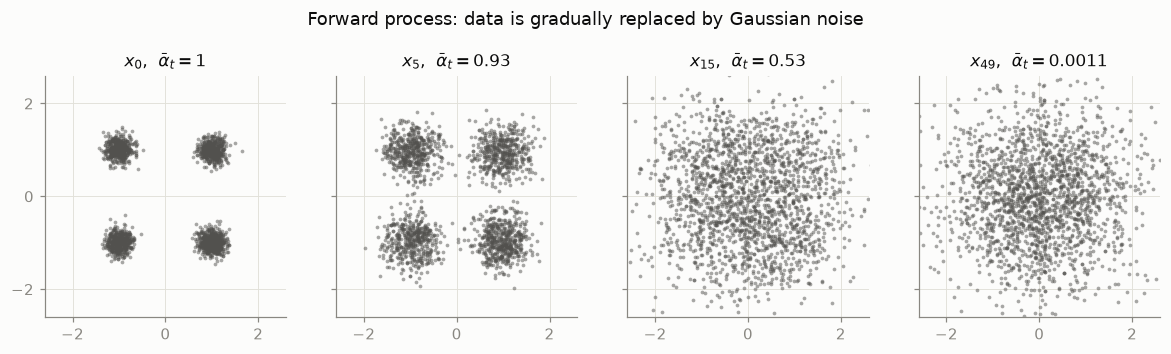

In [3]:
T = 50
betas = torch.linspace(1e-4, 0.25, T)
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

CENTERS = torch.tensor([[1.0, 1.0], [-1.0, 1.0], [-1.0, -1.0], [1.0, -1.0]])


def sample_data(n, generator):
    return CENTERS[torch.randint(0, 4, (n,), generator=generator)] + 0.15 * torch.randn(n, 2, generator=generator)


def noise(x0, t, eps):
    return alpha_bar[t].sqrt()[:, None] * x0 + (1 - alpha_bar[t]).sqrt()[:, None] * eps


reference = sample_data(2000, torch.Generator().manual_seed(99))  # held-out samples for scoring

fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharey=True)
eps = torch.randn(2000, 2, generator=torch.Generator().manual_seed(0))
for ax, t in zip(axes, [0, 5, 15, 49]):
    xt = noise(reference, torch.full((2000,), t), eps)
    scatter_panel(ax, xt, INK_2, rf"$x_{{{t}}}$,  $\bar\alpha_t = {alpha_bar[t]:.2g}$")
fig.suptitle("Forward process: data is gradually replaced by Gaussian noise", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 2. Denoiser, training batches and the NGD closure

The denoiser is an MLP that takes $(x_t, t/T)$ through 3 → 8 → 2 layers with SiLU. That gives **50 parameters**,
so $G$ is $50\times50$, which HHL pads to $64\times64$ (6 system qubits).

Every training step draws a fresh minibatch of $(x_0, t, \varepsilon)$, so NGD estimates $G$ from 256 samples ×
2 output dimensions = 512 residuals. With `metric="gauss_newton"`, the closure returns the residuals, flattened.
It runs only the forward pass and never calls `.backward()`:

```python
opt = NGD(model.parameters(), lr=0.5, damping=1e-3, metric="gauss_newton")
opt.step(lambda: (model(xt, t) - eps).reshape(-1))
```

In [4]:
class Denoiser(nn.Module):
    def __init__(self, hidden=8):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3, hidden), nn.SiLU(), nn.Linear(hidden, 2))

    def forward(self, x, t):
        return self.net(torch.cat([x, (t / T)[:, None]], dim=1))


def make_model():
    torch.manual_seed(0)  # identical initial weights for every optimiser
    return Denoiser()


def training_batch(n, generator):
    x0 = sample_data(n, generator)
    t = torch.randint(0, T, (n,), generator=generator)
    eps = torch.randn(n, 2, generator=generator)
    return noise(x0, t, eps), t, eps


print("parameters:", sum(p.numel() for p in make_model().parameters()))

parameters: 50


## 3. Sampling and scoring

New points come from **ancestral sampling**: start from $x_{T-1}\sim\mathcal N(0, I)$ and repeatedly apply
$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon_\theta(x_t, t)\big) + \sqrt{\beta_t}\,z$.
Each model is scored in two ways:

* the denoising loss on a fixed evaluation batch. Even a perfect model can't reach zero here, because the noise
  isn't fully predictable from $x_t$.
* the **MMD²** (RBF kernel, bandwidth 0.3) between 2,000 generated points and 2,000 held-out data points. Lower is
  better; two independent data samples score about 0.001.

In [5]:
EVAL_BATCH = training_batch(2000, torch.Generator().manual_seed(7))


def eval_loss(model):
    xt, t, eps = EVAL_BATCH
    with torch.no_grad():
        return 0.5 * ((model(xt, t) - eps) ** 2).sum(1).mean().item()


@torch.no_grad()
def generate(model, n=2000, seed=1, keep=()):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 2, generator=g)
    snapshots = {}
    for t in reversed(range(T)):
        if t in keep:
            snapshots[t] = x.clone()
        eps_hat = model(x, torch.full((n,), t))
        x = (x - betas[t] / (1 - alpha_bar[t]).sqrt() * eps_hat) / alphas[t].sqrt()
        if t > 0:
            x = x + betas[t].sqrt() * torch.randn(n, 2, generator=g)
    snapshots["final"] = x
    return snapshots if keep else x


def mmd2(a, b, bandwidth=0.3):
    def k(u, v):
        return torch.exp(-torch.cdist(u, v) ** 2 / (2 * bandwidth**2)).mean()

    return (k(a, a) + k(b, b) - 2 * k(a, b)).item()


print(f"MMD² between two independent data samples: {mmd2(sample_data(2000, torch.Generator().manual_seed(5)), reference):.4f}")

MMD² between two independent data samples: 0.0011


## 4. Train

Every run starts from the same weights and sees the same sequence of minibatches. The NGD runs take 300 steps.
Adam takes 300 steps, and 3,000 more because its steps are much cheaper. The HHL run uses 6 clock qubits, which
makes a 6 + 6 + 1 = 13-qubit circuit per step.

In [6]:
STEPS, BATCH = 300, 256


def train(make_optimizer, steps=STEPS):
    model = make_model()
    opt = make_optimizer(model.parameters())
    g = torch.Generator().manual_seed(1)
    losses = [eval_loss(model)]
    start = time.perf_counter()
    for _ in range(steps):
        xt, t, eps = training_batch(BATCH, g)
        if isinstance(opt, NGD):
            opt.step(lambda: (model(xt, t) - eps).reshape(-1))
        else:
            opt.zero_grad()
            (0.5 * ((model(xt, t) - eps) ** 2).sum(1).mean()).backward()
            opt.step()
        losses.append(eval_loss(model))
    seconds = time.perf_counter() - start
    return {"model": model, "loss": losses, "seconds": seconds, "mmd": mmd2(generate(model), reference)}


LR, DAMPING = 0.5, 1e-3
runs = {
    "Adam": train(lambda p: torch.optim.Adam(p, lr=1e-2)),
    "Adam, 10x steps": train(lambda p: torch.optim.Adam(p, lr=1e-2), steps=10 * STEPS),
    "NGD (direct)": train(lambda p: NGD(p, lr=LR, damping=DAMPING, metric="gauss_newton")),
    "NGD (HHL)": train(lambda p: NGD(p, lr=LR, damping=DAMPING, metric="gauss_newton",
                                     solver=QiskitHHLSolver(num_clock_qubits=6))),
}


def summary(runs):
    print(f"{'run':<34}{'steps':>7}{'eval loss':>11}{'MMD²':>9}{'time (s)':>10}")
    for name, r in runs.items():
        print(f"{name:<34}{len(r['loss']) - 1:>7}{r['loss'][-1]:>11.4f}{r['mmd']:>9.4f}{r['seconds']:>10.2f}")


summary(runs)

run                                 steps  eval loss     MMD²  time (s)
Adam                                  300     0.3972   0.1556      0.17
Adam, 10x steps                      3000     0.3019   0.0544      1.79
NGD (direct)                          300     0.2866   0.0433      1.00
NGD (HHL)                             300     0.4511   0.1890     15.92


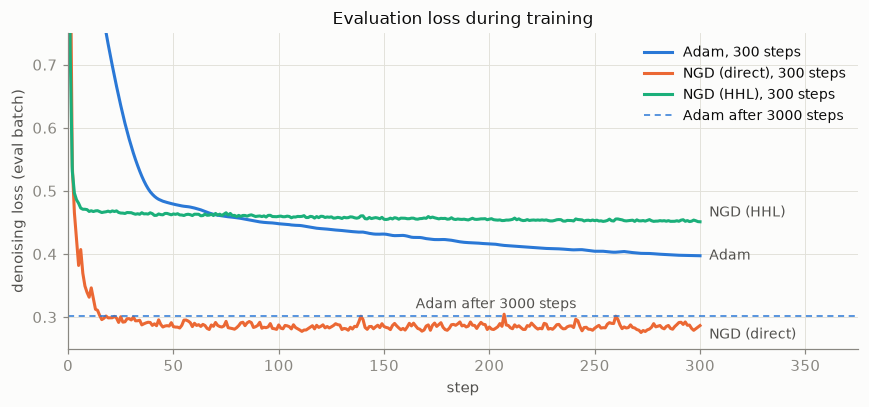

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
steps = np.arange(STEPS + 1)
label_nudge = {"Adam": 0, "NGD (direct)": -6, "NGD (HHL)": 6}
for name in ("Adam", "NGD (direct)", "NGD (HHL)"):
    loss = runs[name]["loss"]
    ax.plot(steps, loss, color=COLORS[name], label=f"{name}, {STEPS} steps")
    ax.annotate(name, (STEPS, loss[-1]), xytext=(6, label_nudge[name]), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)
adam_long = runs["Adam, 10x steps"]["loss"][-1]
ax.axhline(adam_long, color=COLORS["Adam"], linewidth=1, linestyle=(0, (4, 3)), label=f"Adam after {10 * STEPS} steps")
ax.annotate(f"Adam after {10 * STEPS} steps", (STEPS * 0.55, adam_long), xytext=(0, 5), textcoords="offset points",
            fontsize=9, color=INK_2)
ax.set(xlabel="step", ylabel="denoising loss (eval batch)", title="Evaluation loss during training",
       xlim=(0, STEPS * 1.25), ylim=(0.25, 0.75))
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

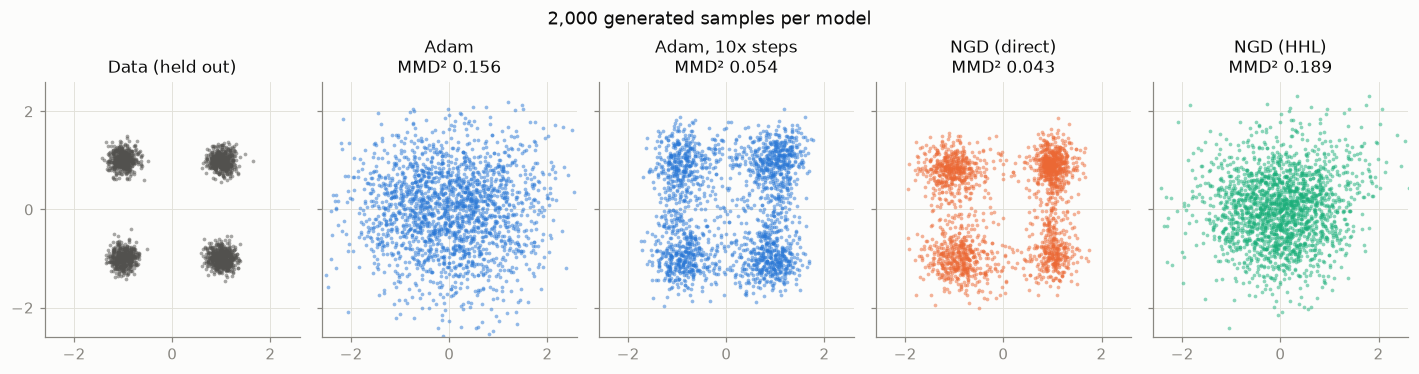

In [8]:
panels = [("Data (held out)", reference, INK_2)] + [
    (f"{name}\nMMD² {runs[name]['mmd']:.3f}", generate(runs[name]["model"]), COLORS[name.split(",")[0]])
    for name in ("Adam", "Adam, 10x steps", "NGD (direct)", "NGD (HHL)")
]
fig, axes = plt.subplots(1, 5, figsize=(13, 3.2), sharey=True)
for ax, (title, points, color) in zip(axes, panels):
    scatter_panel(ax, points, color, title)
fig.suptitle("2,000 generated samples per model", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

The reverse process of the NGD (direct) model, starting from pure noise:

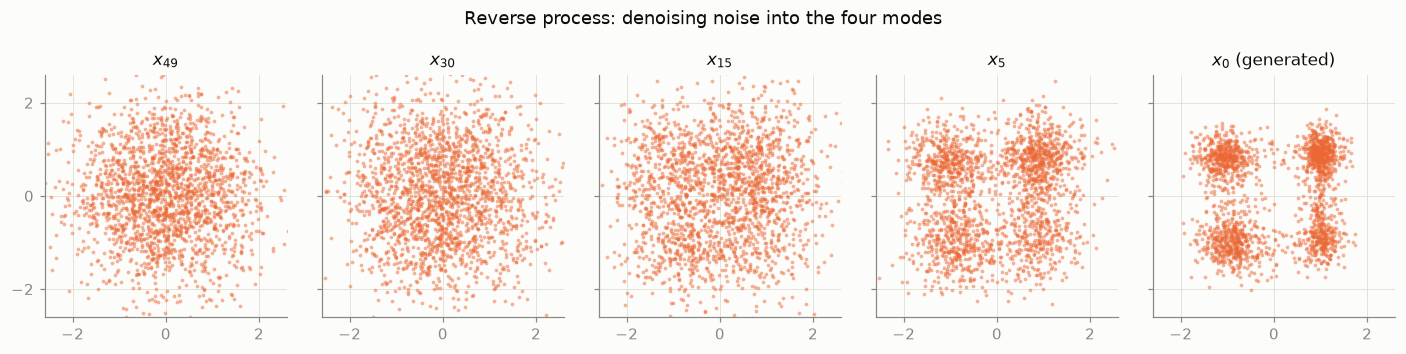

In [9]:
keep = (49, 30, 15, 5)
trajectory = generate(runs["NGD (direct)"]["model"], keep=keep)
fig, axes = plt.subplots(1, 5, figsize=(13, 3), sharey=True)
for ax, key in zip(axes, [*keep, "final"]):
    title = "$x_0$ (generated)" if key == "final" else f"$x_{{{key}}}$"
    scatter_panel(ax, trajectory[key], COLORS["NGD (direct)"], title)
fig.suptitle("Reverse process: denoising noise into the four modes", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## 5. Why does plain HHL lag behind?

HHL resolves eigenvalues only in steps of $\lambda_{\max}/(2^{n_c-1}-1)$ and **drops** anything below half a step.
To see what that means here, record the spectrum of $G+\lambda I$ during a classical NGD run. Any callable works
as a solver, so a recording wrapper around `np.linalg.solve` is enough.

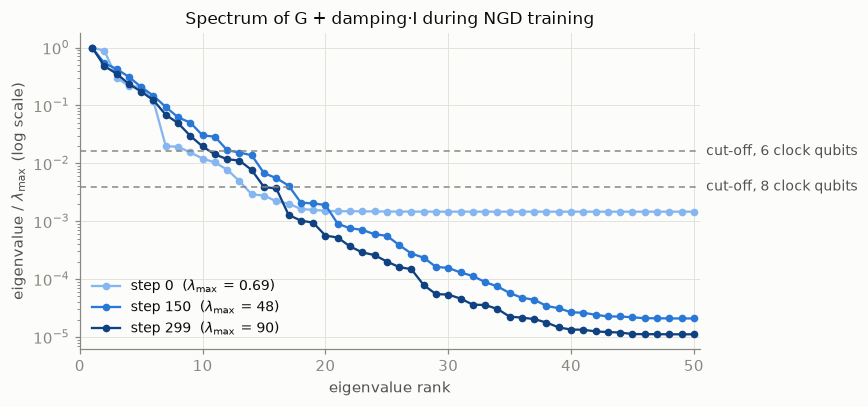

step   0: condition number 6.9e+02; 8 of 50 eigenvalues survive a 6-clock-qubit cut-off
step 150: condition number 4.8e+04; 12 of 50 eigenvalues survive a 6-clock-qubit cut-off
step 299: condition number 9.0e+04; 10 of 50 eigenvalues survive a 6-clock-qubit cut-off


In [10]:
class RecordingSolver:
    def __init__(self, at_steps):
        self.at_steps, self.calls, self.spectra = set(at_steps), 0, {}

    def __call__(self, A, b):
        if self.calls in self.at_steps:
            self.spectra[self.calls] = np.linalg.eigvalsh(A)[::-1]
        self.calls += 1
        return np.linalg.solve(A, b)


recorder = RecordingSolver(at_steps=(0, 150, 299))
train(lambda p: NGD(p, lr=LR, damping=DAMPING, metric="gauss_newton", solver=recorder))

fig, ax = plt.subplots(figsize=(8, 3.8))
for color, (step, spectrum) in zip(TIME_RAMP, recorder.spectra.items()):
    ax.plot(np.arange(1, len(spectrum) + 1), spectrum / spectrum[0], color=color, marker="o", markersize=4,
            linewidth=1.5, label=rf"step {step}  ($\lambda_{{\max}}$ = {spectrum[0]:.2g})")
for nc in (6, 8):
    cutoff = 1 / (2 * (2 ** (nc - 1) - 1))
    ax.axhline(cutoff, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.annotate(f"cut-off, {nc} clock qubits", (51, cutoff), va="center", fontsize=9, color=INK_2,
                annotation_clip=False)
ax.set(yscale="log", xlabel="eigenvalue rank", ylabel=r"eigenvalue / $\lambda_{\max}$ (log scale)",
       title="Spectrum of G + damping·I during NGD training", xlim=(0, 50.5))
ax.legend(loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()

for step, spectrum in recorder.spectra.items():
    kept = int(np.sum(spectrum / spectrum[0] >= 1 / 62))
    print(f"step {step:>3}: condition number {spectrum[0] / spectrum[-1]:.1e}; "
          f"{kept} of {len(spectrum)} eigenvalues survive a 6-clock-qubit cut-off")

The spectrum is steep, and $\lambda_{\max}$ grows by two orders of magnitude as the output layer's weights grow.
With 6 clock qubits, HHL inverts only the top handful of directions and returns *nothing* along the rest. In
effect, that is natural gradient restricted to a low-rank subspace.

`QiskitHHLSolver(..., match_damping_to_clock=True)` fixes this. It solves $(A+\mu I)\,x=b$ with the smallest
$\mu$ that lifts $\lambda_{\min}$ onto the first clock step,

$$\mu = \max\!\Big(0,\ \frac{\lambda_{\max} - k_{\max}\lambda_{\min}}{k_{\max}-1}\Big), \qquad k_{\max} = 2^{n_c-1}-1,$$

so every direction is inverted at least approximately instead of being dropped. The $A$ oracle is unchanged,
because $e^{i(A+\mu I)t} = e^{i\mu t}e^{iAt}$. Inside each controlled $U^{2^j}$, the global phase $e^{i\mu t 2^j}$
becomes a phase gate on clock qubit $j$. To separate HHL's own error from the effect of the extra damping, the
same $\mu$ is also applied to a classical solve.

In [11]:
hhl_matched = QiskitHHLSolver(num_clock_qubits=6, match_damping_to_clock=True)


def classical_same_shift(A, b):
    evals = np.linalg.eigvalsh(A)
    mu = hhl_matched.clock_matched_shift(evals[0], evals[-1])
    return np.linalg.solve(A + mu * np.eye(len(b)), b)


runs["NGD (HHL) + clock-matched damping"] = train(lambda p: NGD(
    p, lr=LR, damping=DAMPING, metric="gauss_newton", solver=hhl_matched))
runs["NGD (classical) + same damping"] = train(lambda p: NGD(
    p, lr=LR, damping=DAMPING, metric="gauss_newton", solver=classical_same_shift))
summary(runs)
info = hhl_matched.last_info
print(f"\nlast HHL step: damping shift mu = {info.damping_shift:.3g}, success probability {info.success_probability:.2f}")

run                                 steps  eval loss     MMD²  time (s)
Adam                                  300     0.3972   0.1556      0.17
Adam, 10x steps                      3000     0.3019   0.0544      1.79
NGD (direct)                          300     0.2866   0.0433      1.00
NGD (HHL)                             300     0.4511   0.1890     15.92
NGD (HHL) + clock-matched damping     300     0.3066   0.0656     16.06
NGD (classical) + same damping        300     0.3073   0.0665      1.03

last HHL step: damping shift mu = 0.16, success probability 0.03


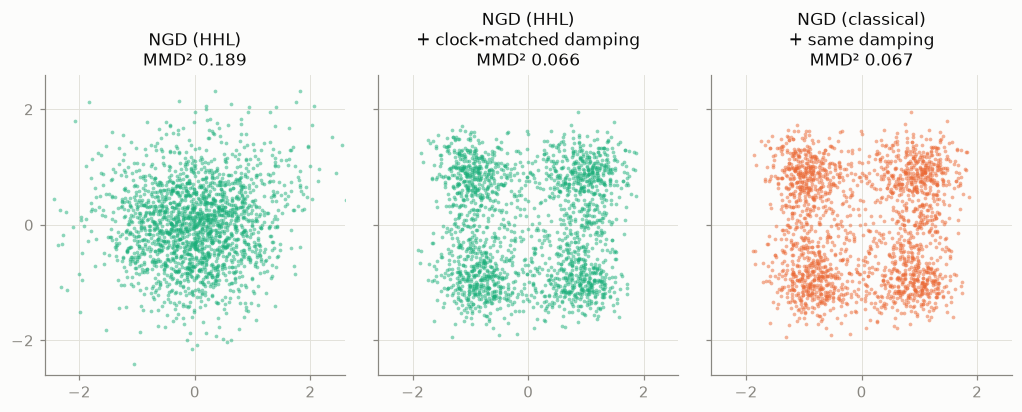

In [12]:
names = ["NGD (HHL)", "NGD (HHL) + clock-matched damping", "NGD (classical) + same damping"]
fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.4), sharey=True)
for ax, name in zip(axes, names):
    color = COLORS["NGD (direct)"] if "classical" in name else COLORS["NGD (HHL)"]
    scatter_panel(ax, generate(runs[name]["model"]), color, f"{name.replace(' + ', chr(10) + '+ ')}\nMMD² {runs[name]['mmd']:.3f}")
fig.tight_layout()
plt.show()

## Takeaways

- **NGD trains this diffusion model far faster per step than Adam.** After 300 steps, NGD with a direct solve
  reached MMD² 0.043, against 0.156 for Adam. That also beats Adam after 3,000 steps (0.054), in less wall-clock
  time here, because 50 parameters make the $50\times50$ solve cheap.
- **Plain HHL with 6 clock qubits was worse than Adam** (MMD² 0.189). The Gauss-Newton spectrum is steep and gets
  steeper as training goes on: the condition number rises from about $7\times10^2$ to $9\times10^4$. Only 8–12 of
  the 50 eigenvalues stay above the 6-qubit cut-off, so HHL returns no step at all along most directions.
- **Clock-matched damping fixes this, and isolates HHL's own error.** `match_damping_to_clock=True` brought HHL
  to MMD² 0.0656, and a classical solve of the *same* shifted system scored 0.0665. Once the spectrum fits the clock, the quantum solve is accurate. The remaining gap to the direct NGD
  run comes from the heavier damping, which costs curvature information.
- **For quantum linear solvers, conditioning is the bottleneck, not system size.** A 6-clock-qubit HHL handles
  condition numbers up to about 31. Each extra clock qubit doubles that, but it also deepens the circuit and lowers
  the postselection probability. That matters on shot-based or noisy backends (see the README's backend table).

All runs use one seed, so differences of about 0.01 in MMD² shouldn't be over-read.